In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [67]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

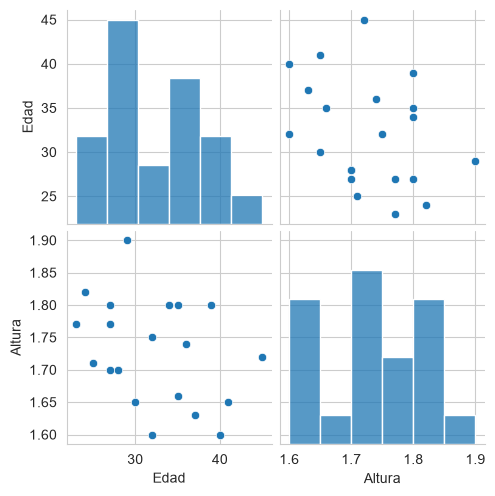

In [68]:
sns.pairplot(df[["Edad", "Altura"]])





### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [69]:
df = pd.DataFrame(lista_alumnos, columns=["Nombre", "Edad", "Altura"])
df


,Nombre,Edad,Altura
0,Leonardo S,24,1.82
1,Piero T,25,1.71
2,Marta B,35,1.66
3,Silvia P,37,1.63
4,Faro Z,29,1.90
5,Miguel N,27,1.80
6,Alejandro M,28,1.70
7,Cristina M,32,1.60
8,Francisco P,36,1.74
9,Jorge D,45,1.72


### Entrena un modelo de regresión lineal

In [70]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [71]:
x = df[["Edad"]]
x

,Edad
0,24
1,25
2,35
3,37
4,29
5,27
6,28
7,32
8,36
9,45


In [72]:
y = df["Altura"]
y


0     1.82
1     1.71
2     1.66
3     1.63
4     1.90
5     1.80
6     1.70
7     1.60
8     1.74
9     1.72
10    1.65
11    1.65
12    1.60
13    1.80
14    1.77
15    1.75
16    1.70
17    1.80
18    1.77
19    1.70
20    1.80
Name: Altura, dtype: float64

In [73]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=4, random_state=42)


In [74]:
x_train


,Edad
8,36
5,27
11,30
3,37
18,27
16,27
13,39
2,35
9,45
20,35


In [75]:
lr = LinearRegression()


In [76]:
lr.fit(x_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Edad']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.854
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [77]:
lr.intercept_

np.float64(1.8538095697472503)

In [78]:
'''a medida que la edad aumenta, la altura disminuye en promedio 0.004 metros (0,4 cm)'''
lr.coef_

array([-0.00415879])

In [79]:
x_test

,Edad
0,24
17,34
15,32
1,25


In [80]:
lr.predict(x_test)  


array([1.75399865, 1.71241077, 1.72072834, 1.74983986])

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [81]:
errores = y_test - lr.predict(x_test)
errores


0     0.066001
17    0.087589
15    0.029272
1    -0.039840
Name: Altura, dtype: float64

In [82]:
'''con esto podemos ver la diferencia entre el valor real y el valor predicho por el modelo'''
df_2 = df
df_2['prediccion'] = lr.predict(df_2[['Edad']])
df_2['error'] = df_2['Altura'] - lr.predict(df_2[['Edad']])
df_2

,Nombre,Edad,Altura,prediccion,error
0,Leonardo S,24,1.82,1.753999,0.066001
1,Piero T,25,1.71,1.749840,-0.039840
2,Marta B,35,1.66,1.708252,-0.048252
3,Silvia P,37,1.63,1.699934,-0.069934
4,Faro Z,29,1.90,1.733205,0.166795
5,Miguel N,27,1.80,1.741522,0.058478
6,Alejandro M,28,1.70,1.737363,-0.037363
7,Cristina M,32,1.60,1.720728,-0.120728
8,Francisco P,36,1.74,1.704093,0.035907
9,Jorge D,45,1.72,1.666664,0.053336


In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, root_mean_squared_error,r2_score

mean_absolute_error (MAE)	Calcula el promedio de las diferencias absolutas entre valores reales y predichos.	Indica cuánto se equivoca el modelo, en las mismas unidades del dato. Si predice altura en cm y el MAE es 3, el error medio es de unos 3 cm.

mean_squared_error (MSE)	Calcula el promedio de los errores al cuadrado.	Penaliza más los errores grandes. Sus unidades quedan al cuadrado, así que es menos intuitivo: para altura en cm, queda en cm².

mean_absolute_percentage_error (MAPE)	Calcula el error absoluto medio relativo al valor real.	Permite expresar el error como porcentaje. En scikit-learn, el resultado es una proporción: por ejemplo, 0.08 equivale a 8 % al multiplicar por 100. Puede ser poco fiable si los valores reales son cero o muy cercanos a cero.

root_mean_squared_error (RMSE)	Es la raíz cuadrada del MSE.	Penaliza los errores grandes como el MSE, pero vuelve a las unidades originales. Para altura, se expresa en cm.

r2_score (R²)	Mide qué tan bien las predicciones representan la variación de los valores reales.	1 es perfecto; 0 equivale aproximadamente a predecir siempre el promedio; puede ser negativo si el modelo lo hace peor que esa referenci

In [84]:
y_pred = lr.predict(df_2[['Edad']])

In [85]:
mean_absolute_percentage_error(df_2['Altura'], y_pred)

0.03663772184396239

In [86]:
mean_absolute_error(df_2['Altura'], y_pred)

0.06345888114072566

In [87]:
#mean_squared_error(df_2['Altura'], y_pred)

In [88]:
root_mean_squared_error(df_2['Altura'], y_pred)

0.07312052667614101

In [89]:
r2_score(df_2['Altura'], y_pred)

0.10053573020685702

<Axes: xlabel='Edad', ylabel='Altura'>

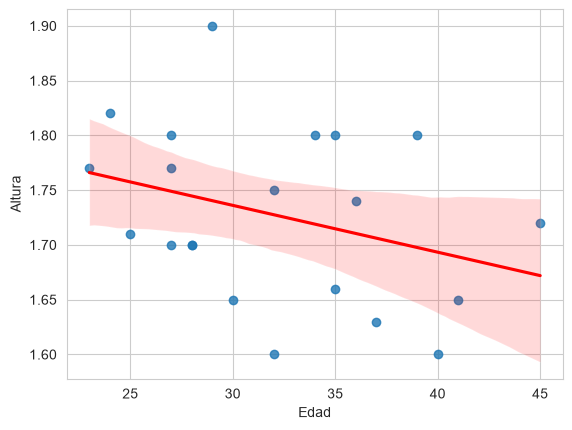

In [90]:
sns.regplot(x=df['Edad'], y=df['Altura'], line_kws={"color": "red"})

In [38]:
'''error absoluto medio
Cuánto se equivoca el modelo en promedio, en la misma unidad que la variable.'''
mae = abs(errores).mean()*100
mae

np.float64(5.318486080700664)

In [ ]:
'''error porcentual absoluto medio
Qué tan grande fue el error relativo al valor real, en porcentaje
'''
mape = (abs(errores) / y_test).mean() * 100
mape

np.float64(2.9943007687355165)

In [ ]:
'''error cuadrático medio
Penaliza mucho más los errores grandes que los pequeños'''
mse = (errores ** 2).mean()
mse

np.float64(0.0033126493607306537)

In [ ]:
'''raíz del error cuadrático medio
Es como MSE, pero vuelve a la misma unidad que la variable original'''
rmse = mse ** 0.5
rmse


np.float64(0.057555619714591326)